# Figure S3: density change averaged over 60-65N in 8xCO2

Annual-mean surface T and S averaged over all Atlantic + GIN cells in 60-65N, relative to the same average in the
control run.

Inputs: `ANNmean_TS_cells_8x_natl20-80N.nc`, `surface_TS_sigma1_cells_ctrl_natl20-80N.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
years, change = common.band_mean_breakdown((60, 65))
for phase, (start, end) in {'collapsed 1000-2000': (1000, 2000), 'recovered 3000-4000': (3000, 4000)}.items():
    in_phase = (years >= start) & (years < end)
    print(f"{phase}: d_sigma {change['total'][in_phase].mean():+.2f} = temperature "
          f"{change['temperature'][in_phase].mean():+.2f} + salinity {change['salinity'][in_phase].mean():+.2f}")

collapsed 1000-2000: d_sigma -3.50 = temperature -0.58 + salinity -2.94
recovered 3000-4000: d_sigma -2.02 = temperature -1.63 + salinity -0.40


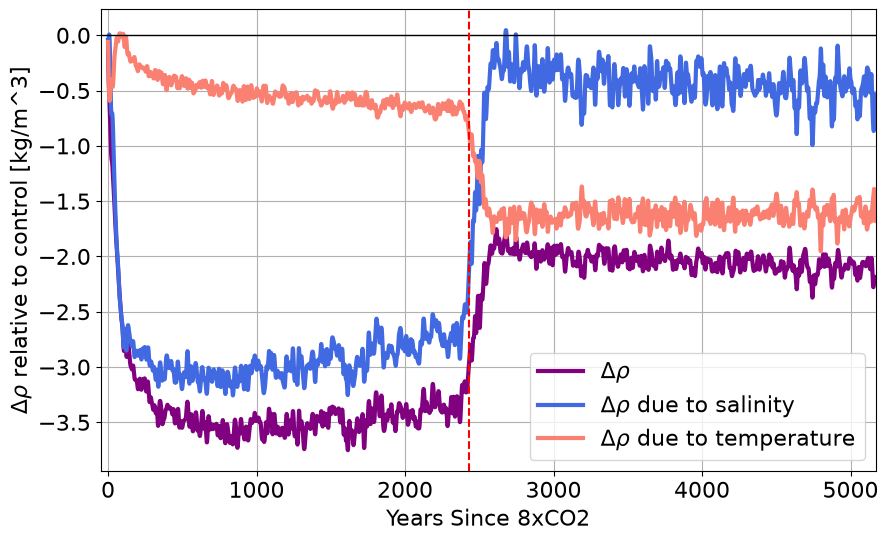

In [3]:
def plot_breakdown(ax, years, change, linewidth=3):
    """Draw the smoothed density change and its salinity and temperature parts on ax; zero is the control mean."""
    curves = [('total', '$\\Delta\\rho$', 'purple'),
              ('salinity', '$\\Delta\\rho$ due to salinity', 'royalblue'),
              ('temperature', '$\\Delta\\rho$ due to temperature', 'salmon')]
    for key, label, color in curves:
        ax.plot(years, common.butterworth_lowpass(change[key]), label=label, linewidth=linewidth, color=color)
    ax.axhline(0, color='k', linewidth=1)
    ax.grid()


fig, ax = plt.subplots(figsize=(10, 6))
plot_breakdown(ax, years, change)
ax.axvline(common.RECOVERY_YEAR, color='red', linestyle='--')
ax.set_xlim(years[0] - common.X_START_PAD, years[-1])
ax.set_xlabel('Years Since 8xCO2')
ax.set_ylabel('$\\Delta \\rho$ relative to control [kg/m^3]')
ax.legend()
plt.savefig(common.figure_path('figS3_density_breakdown_60_65N.png'), dpi=150, bbox_inches='tight')
plt.show()